
# BMMC visualization notebook for ATLAS early-stopping results

This notebook is designed for your server-side results under:

- `baseline/seed_1234/BMMC/pair_xxx/`
- `consensus/seed_1234/BMMC/pair_xxx/`

It helps you visualize **all pairing ratios (0/20/40/60/80/100)** in a Figure-3-like style, using a **pink–blue color scheme**, for three tasks:

1. **A. Cross-modal alignment**
2. **B. Cross-omics prediction**
3. **C. Trajectory inference**

The notebook is written to be **robust to slightly different `predictions.npz` field names**. It first inspects the saved keys and then tries to infer the correct arrays automatically.

> Recommended workflow: run the notebook **cell by cell**. First inspect one ratio, confirm the detected keys are correct, and then generate all figures.


In [1]:

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    from umap import UMAP
    HAS_UMAP = True
except Exception as e:
    print(f"[Warning] umap-learn is unavailable: {e}")
    HAS_UMAP = False

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [2]:

# =========================
# User configuration
# =========================
RESULT_ROOT = Path('/data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01')
DATASET_NAME = 'BMMC'
SEED = 'seed_1234'
ARMS = ['consensus', 'baseline']   # top row first, bottom row second
PAIR_RATIOS = [0, 20, 40, 60, 80, 100]

# Optional external label file, only needed if predictions.npz does not contain stage/cell-type labels.
# If you already know the exact CSV, fill it here. Otherwise keep None and inspect first.
EXTERNAL_LABEL_CSV = None
EXTERNAL_LABEL_CELL_ID_COL = 'cell_id'
EXTERNAL_LABEL_COL = 'cell_type'

# Output directory for figures
FIG_ROOT = RESULT_ROOT / 'visualization_BMMC_figure3_like'
FIG_ROOT.mkdir(parents=True, exist_ok=True)

# Colors: pink / blue family, consistent with your reference image
PINK = '#E78AC3'
PINK_DARK = '#C51B8A'
PINK_LIGHT = '#F4CAE4'
BLUE = '#74A9CF'
BLUE_DARK = '#2B8CBE'
BLUE_LIGHT = '#C6DBEF'
GRAY = '#6C757D'

# scatter density controls
MAX_SCATTER_POINTS = 8000
MAX_ALIGNMENT_POINTS_PER_MODALITY = 2500
RANDOM_SEED = 1234
rng = np.random.default_rng(RANDOM_SEED)


In [3]:

# =========================
# Helpers: file loading / inspection
# =========================

def pair_tag(ratio: int) -> str:
    return f'pair_{ratio:03d}'


def run_dir(arm: str, ratio: int) -> Path:
    return RESULT_ROOT / arm / SEED / DATASET_NAME / pair_tag(ratio)


def load_json(path: Path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


def load_npz_dict(path: Path):
    with np.load(path, allow_pickle=False) as data:
        return {k: data[k] for k in data.files}


def inspect_run(arm: str, ratio: int):
    rd = run_dir(arm, ratio)
    print(f'\n===== {arm} | ratio={ratio} =====')
    print('Run dir:', rd)
    if not rd.exists():
        print('[Missing run directory]')
        return None

    metrics_path = rd / 'metrics.json'
    pred_path = rd / 'predictions.npz'
    summary_path = rd / 'summary.csv'
    estop_path = rd / 'early_stopping_summary.json'
    part_path = rd / 't3_validation_partition.json'

    for p in [metrics_path, pred_path, summary_path, estop_path, part_path]:
        print(f'  {p.name:<30} ->', 'OK' if p.exists() else 'MISSING')

    if pred_path.exists():
        pred = load_npz_dict(pred_path)
        print('  predictions.npz keys:')
        for k, v in pred.items():
            print(f'    - {k:<20} shape={getattr(v, "shape", None)} dtype={getattr(v, "dtype", None)}')
    else:
        pred = None

    if metrics_path.exists():
        metrics = load_json(metrics_path)
        print('  metrics keys:', list(metrics.keys()))
        print('  T1:', metrics.get('T1', {}))
        print('  T2:', metrics.get('T2', {}))
        print('  T3:', metrics.get('T3', {}))
        print('  protocol:', metrics.get('protocol', {}))
    else:
        metrics = None

    return {'run_dir': rd, 'pred': pred, 'metrics': metrics}


In [4]:

# Inspect one example first
example = inspect_run('consensus', 20)



===== consensus | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 30) dtype=float64
    - t1_pred_pca          shape=(6191, 30) dtype=float64
    - time                 shape=(6191,) dtype=float32
    - time_head            shape=(6191,) dtype=float32
    - labels               shape=(6191,) dtype=<U20
  metrics keys: [

In [5]:

# Inspect all ratios for both arms
for ratio in PAIR_RATIOS:
    for arm in ARMS:
        inspect_run(arm, ratio)



===== consensus | ratio=0 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_000
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(5161,) dtype=<U25
    - z_atac               shape=(5161, 32) dtype=float32
    - z_rna                shape=(5161, 32) dtype=float32
    - h_fused              shape=(5161, 32) dtype=float32
    - pred_rna             shape=(5161, 12093) dtype=float32
    - true_rna             shape=(5161, 12093) dtype=float32
    - t1_true_pca          shape=(5161, 30) dtype=float64
    - t1_pred_pca          shape=(5161, 30) dtype=float64
    - time                 shape=(5161,) dtype=float32
    - time_head            shape=(5161,) dtype=float32
    - labels               shape=(5161,) dtype=<U20
  metrics keys: ['

In [6]:

# =========================
# Helpers: robust key guessing
# =========================

def first_existing_key(d, candidates):
    for k in candidates:
        if k in d:
            return k
    return None


def maybe_subsample(X, n_max, seed=1234):
    if X is None:
        return None, None
    n = len(X)
    if n <= n_max:
        idx = np.arange(n)
        return X, idx
    rr = np.random.default_rng(seed)
    idx = rr.choice(n, size=n_max, replace=False)
    idx = np.sort(idx)
    return X[idx], idx


def compute_2d_embedding(X, random_state=1234):
    if X.ndim != 2:
        raise ValueError(f'Expected 2D array, got shape={X.shape}')
    if X.shape[1] == 2:
        return X
    Xs = StandardScaler(with_mean=True, with_std=True).fit_transform(X)
    if HAS_UMAP:
        reducer = UMAP(n_components=2, n_neighbors=20, min_dist=0.35, metric='euclidean', random_state=random_state)
        return reducer.fit_transform(Xs)
    else:
        print('[Info] Falling back to PCA(2) because UMAP is unavailable.')
        return PCA(n_components=2, random_state=random_state).fit_transform(Xs)


def get_alignment_embeddings(pred):
    # Try modality-specific latent embeddings first.
    atac_key = first_existing_key(pred, ['z_atac', 'h_atac', 'atac_latent', 'latent_atac', 'embed_atac'])
    rna_key  = first_existing_key(pred, ['z_rna', 'h_rna', 'rna_latent', 'latent_rna', 'embed_rna'])
    if atac_key and rna_key:
        return pred[atac_key], pred[rna_key], {'atac_key': atac_key, 'rna_key': rna_key, 'mode': 'modality_specific'}

    # Fallback: use fused embedding if only one latent is saved.
    fused_key = first_existing_key(pred, ['h_fused', 'h', 'z', 'latent', 'embedding'])
    if fused_key:
        fused = pred[fused_key]
        # duplicate to emulate two modalities only for visualization, with tiny jitter
        jitter = np.random.default_rng(1234).normal(0, 1e-3, size=fused.shape)
        return fused + jitter, fused - jitter, {'atac_key': fused_key, 'rna_key': fused_key, 'mode': 'fused_duplicated'}

    raise KeyError('No suitable embedding keys found for alignment visualization.')


def get_prediction_arrays(pred):
    y_true_key = first_existing_key(pred, ['y_true', 'rna_true', 'true_rna', 'target_true', 'x_true'])
    y_pred_key = first_existing_key(pred, ['y_pred', 'rna_pred', 'pred_rna', 'target_pred', 'x_pred'])
    if y_true_key is None or y_pred_key is None:
        raise KeyError('Could not find true/predicted RNA arrays in predictions.npz')
    y_true = pred[y_true_key]
    y_pred = pred[y_pred_key]
    return y_true, y_pred, {'true_key': y_true_key, 'pred_key': y_pred_key}


def get_time_array(pred, prefer='time'):
    if prefer in pred:
        return pred[prefer], prefer
    for k in ['time', 'time_head', 't', 'pseudotime', 'latent_time']:
        if k in pred:
            return pred[k], k
    raise KeyError('Could not find predicted time array in predictions.npz')


def get_cell_ids(pred):
    key = first_existing_key(pred, ['cell_ids', 'val_cell_ids', 'cells', 'obs_names'])
    return pred.get(key, None), key


def get_stage_or_label_array(pred):
    for k in ['stage', 'stages', 'stage_numeric', 'labels', 'label', 'cell_type', 'cell_types']:
        if k in pred:
            return pred[k], k
    return None, None


In [7]:

# Optional external-label loader for trajectory plots.
# This is only used when predictions.npz does not contain stage or cell-type labels.

def load_external_labels(csv_path, cell_id_col='cell_id', label_col='cell_type'):
    csv_path = Path(csv_path)
    if not csv_path.exists():
        raise FileNotFoundError(csv_path)
    df = pd.read_csv(csv_path)
    if cell_id_col not in df.columns or label_col not in df.columns:
        raise KeyError(f'Columns not found in {csv_path}: {cell_id_col}, {label_col}')
    return df[[cell_id_col, label_col]].copy()


def attach_labels_from_external(pred, external_df, cell_id_col='cell_id', label_col='cell_type'):
    cell_ids, cell_key = get_cell_ids(pred)
    if cell_ids is None:
        raise KeyError('predictions.npz does not contain cell ids; cannot merge external labels.')
    cell_ids = pd.Series(cell_ids.astype(str), name=cell_id_col)
    tmp = pd.DataFrame({cell_id_col: cell_ids})
    merged = tmp.merge(external_df[[cell_id_col, label_col]], how='left', on=cell_id_col)
    labels = merged[label_col].to_numpy()
    return labels, {'source': 'external_csv', 'cell_key': cell_key, 'label_col': label_col}


In [10]:

# =========================
# Plot A: cross-modal alignment
# =========================

def plot_alignment_panel(ax_embed, ax_type, pred, title_prefix=''):
    atac, rna, meta = get_alignment_embeddings(pred)

    atac, idx_a = maybe_subsample(atac, MAX_ALIGNMENT_POINTS_PER_MODALITY, seed=1234)
    rna, idx_r = maybe_subsample(rna, MAX_ALIGNMENT_POINTS_PER_MODALITY, seed=5678)

    Z = np.vstack([atac, rna])
    uv = compute_2d_embedding(Z, random_state=1234)
    uv_a = uv[:len(atac)]
    uv_r = uv[len(atac):]

    ax_embed.scatter(uv_a[:, 0], uv_a[:, 1], s=4, c=PINK, alpha=0.55, linewidths=0, label='ATAC')
    ax_embed.scatter(uv_r[:, 0], uv_r[:, 1], s=4, c=BLUE, alpha=0.55, linewidths=0, label='RNA')
    ax_embed.set_title(f'{title_prefix} Cross-modal alignment', fontsize=12)
    ax_embed.set_xlabel('UMAP 1' if HAS_UMAP else 'Dim 1')
    ax_embed.set_ylabel('UMAP 2' if HAS_UMAP else 'Dim 2')
    ax_embed.spines[['top', 'right']].set_visible(False)
    ax_embed.set_xticks([])
    ax_embed.set_yticks([])
    handles = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor=PINK, markersize=6, label='ATAC'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor=BLUE, markersize=6, label='RNA'),
    ]
    ax_embed.legend(handles=handles, loc='upper left', frameon=False, fontsize=9, ncol=2, handlelength=0.8, columnspacing=0.8)

    labels, label_key = get_stage_or_label_array(pred)
    if labels is None and EXTERNAL_LABEL_CSV is not None:
        labels, _ = attach_labels_from_external(pred, load_external_labels(EXTERNAL_LABEL_CSV, EXTERNAL_LABEL_CELL_ID_COL, EXTERNAL_LABEL_COL), EXTERNAL_LABEL_CELL_ID_COL, EXTERNAL_LABEL_COL)
        label_key = 'external_label'

    if labels is not None:
        labels = labels.astype(str)
        # use the same subsample as ATAC if possible; otherwise just display full labels if lengths match fused embeddings
        if len(labels) == len(pred[first_existing_key(pred, ['h_fused', 'h', 'z', 'latent', 'embedding', 'z_atac', 'h_atac'])]):
            lab_small = labels[:len(atac)] if len(labels) >= len(atac) else labels
        else:
            lab_small = labels[:len(atac)]

        # If lengths mismatch badly, just color the first min(n,label) points.
        n_show = min(len(uv_a), len(lab_small))
        unique_labels = pd.unique(lab_small[:n_show])
        cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
        label_to_color = {lab: cmap(i) for i, lab in enumerate(unique_labels)}
        for lab in unique_labels:
            m = (lab_small[:n_show] == lab)
            ax_type.scatter(uv_a[:n_show][m, 0], uv_a[:n_show][m, 1], s=4, color=label_to_color[lab], alpha=0.65, linewidths=0, label=lab)
        ax_type.set_title(f'{title_prefix} Cell-type layout', fontsize=12)
        ax_type.set_xlabel('UMAP 1' if HAS_UMAP else 'Dim 1')
        ax_type.set_ylabel('UMAP 2' if HAS_UMAP else 'Dim 2')
        ax_type.spines[['top', 'right']].set_visible(False)
        ax_type.set_xticks([])
        ax_type.set_yticks([])
        ax_type.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=7, ncol=2, markerscale=2.0, handlelength=0.6)
    else:
        ax_type.text(0.5, 0.5, 'No cell-type labels found for alignment companion plot.', ha='center', va='center', fontsize=10)
        ax_type.set_axis_off()

    return meta


/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))


Alignment meta: {'atac_key': 'z_atac', 'rna_key': 'z_rna', 'mode': 'modality_specific'}


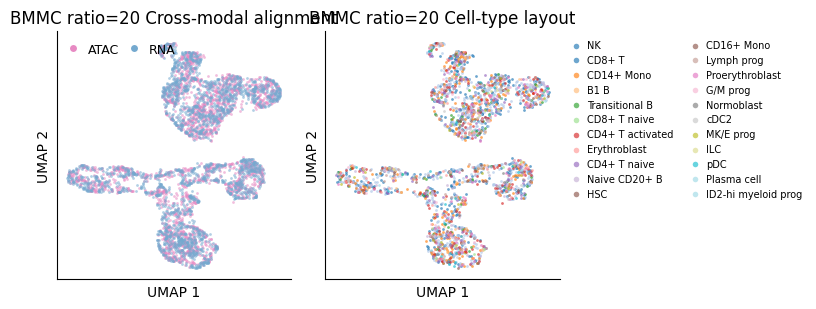

In [11]:

# Test A-plot on one run
ratio = 20
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
pred = load_npz_dict(run_dir('consensus', ratio) / 'predictions.npz')
metaA = plot_alignment_panel(axes[0], axes[1], pred, title_prefix=f'BMMC ratio={ratio}')
print('Alignment meta:', metaA)
plt.tight_layout()
plt.show()


In [16]:

# =========================
# Plot B: cross-omics prediction
# =========================

def flatten_for_scatter(y_true, y_pred, max_points=MAX_SCATTER_POINTS, seed=1234):
    yt = np.ravel(y_true)
    yp = np.ravel(y_pred)
    err = np.abs(yp - yt)
    n = len(yt)
    if n > max_points:
        rr = np.random.default_rng(seed)
        idx = rr.choice(n, size=max_points, replace=False)
        yt = yt[idx]
        yp = yp[idx]
        err = err[idx]
    return yt, yp, err


def plot_prediction_panel(ax_scatter, ax_error, pred, metrics=None, title_prefix=''):
    y_true, y_pred, meta = get_prediction_arrays(pred)
    yt, yp, err = flatten_for_scatter(y_true, y_pred)

    mn = float(min(yt.min(), yp.min()))
    mx = float(max(yt.max(), yp.max()))

    ax_scatter.scatter(yt, yp, s=2, c=BLUE_LIGHT, alpha=0.55, linewidths=0)
    ax_scatter.plot([mn, mx], [mn, mx], linestyle='--', color=PINK_DARK, linewidth=1.0)
    ax_scatter.set_xlabel('True RNA')
    ax_scatter.set_ylabel('Predicted RNA')
    ax_scatter.set_title(f'{title_prefix} Cross-omics prediction', fontsize=12)
    ax_scatter.spines[['top', 'right']].set_visible(False)

    t2 = (metrics or {}).get('T2', {})
    pear = t2.get('Pearson', t2.get('Pearson_cell', None))
    rmse = t2.get('RMSE', None)
    if pear is not None and rmse is not None:
        pearson_text = (
            f"Pearson = {pear * 100:.1f}"
            if pear <= 1.5 else f"Pearson = {pear:.1f}"
        )

        ax_scatter.text(
            0.05, 0.95,
            f"{pearson_text}\nRMSE = {rmse:.3f}",
            transform=ax_scatter.transAxes,
            ha='left',
            va='top',
            fontsize=10,
            bbox=dict(
                boxstyle='round,pad=0.3',
                facecolor='#EEF2F7',
                edgecolor='#B8C2CC',
                alpha=0.9
            )
        )

    # Error visualization: x-axis = sampled point index, y-axis = absolute error
    order = np.argsort(err)
    ax_error.scatter(np.arange(len(err)), err[order], s=2, c=BLUE, alpha=0.35, linewidths=0)
    q95 = float(np.quantile(err, 0.95))
    ax_error.axhline(q95, linestyle='--', color=PINK_DARK, linewidth=1.0, alpha=0.9)
    ax_error.set_xlabel('Sampled features')
    ax_error.set_ylabel('Prediction error')
    ax_error.set_title('Error distribution', fontsize=12)
    ax_error.spines[['top', 'right']].set_visible(False)

    return meta



===== consensus | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 30) dtype=float64
    - t1_pred_pca          shape=(6191, 30) dtype=float64
    - time                 shape=(6191,) dtype=float32
    - time_head            shape=(6191,) dtype=float32
    - labels               shape=(6191,) dtype=<U20
  metrics keys: [

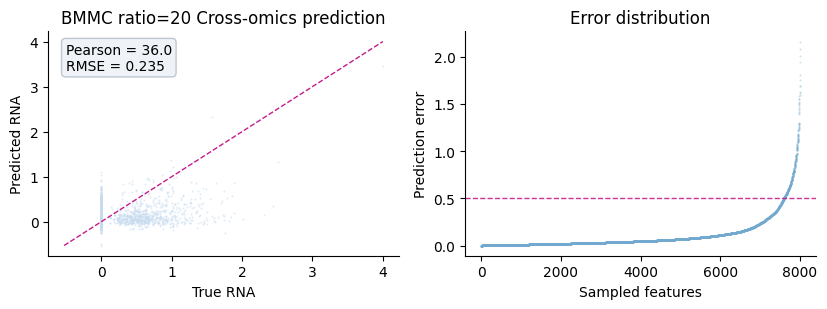

In [17]:

# Test B-plot on one run
ratio = 20
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2))
obj = inspect_run('consensus', ratio)
metaB = plot_prediction_panel(axes[0], axes[1], obj['pred'], obj['metrics'], title_prefix=f'BMMC ratio={ratio}')
print('Prediction meta:', metaB)
plt.tight_layout()
plt.show()


In [20]:

# =========================
# Plot C: trajectory inference
# =========================

def label_to_numeric_stages(labels):
    labels = pd.Series(labels.astype(str))
    unique = labels.dropna().unique().tolist()
    # Simple deterministic ordering; if you have a biological order, replace here.
    stage_map = {lab: i for i, lab in enumerate(unique)}
    numeric = labels.map(stage_map).to_numpy(dtype=float)
    return numeric, stage_map


def plot_trajectory_panel(ax_umap, ax_stage, pred, metrics=None, title_prefix=''):
    time, time_key = get_time_array(pred, prefer='time')
    time = np.asarray(time).reshape(-1)

    # Layout for visualization: try fused embedding first, else use prediction space
    emb_key = first_existing_key(pred, ['h_fused', 'h', 'z', 'latent', 'embedding', 'z_atac', 'h_atac'])
    if emb_key is None:
        y_true, _, _ = get_prediction_arrays(pred)
        X_layout = y_true if y_true.ndim == 2 else y_true.reshape(-1, 1)
    else:
        X_layout = pred[emb_key]
    X2 = compute_2d_embedding(X_layout, random_state=4321)

    sc = ax_umap.scatter(X2[:, 0], X2[:, 1], c=time, cmap='PuRd', s=4, alpha=0.75, linewidths=0)
    cb = plt.colorbar(sc, ax=ax_umap, fraction=0.046, pad=0.04)
    cb.set_label('Predicted time')
    ax_umap.set_title(f'{title_prefix} Predicted trajectory', fontsize=12)
    ax_umap.set_xlabel('UMAP 1' if HAS_UMAP else 'Dim 1')
    ax_umap.set_ylabel('UMAP 2' if HAS_UMAP else 'Dim 2')
    ax_umap.spines[['top', 'right']].set_visible(False)
    ax_umap.set_xticks([])
    ax_umap.set_yticks([])

    labels, label_key = get_stage_or_label_array(pred)
    if labels is None and EXTERNAL_LABEL_CSV is not None:
        labels, _ = attach_labels_from_external(pred, load_external_labels(EXTERNAL_LABEL_CSV, EXTERNAL_LABEL_CELL_ID_COL, EXTERNAL_LABEL_COL), EXTERNAL_LABEL_CELL_ID_COL, EXTERNAL_LABEL_COL)
        label_key = 'external_label'

    if labels is None:
        ax_stage.text(0.5, 0.5, 'No reference stage / cell-type labels found. Set EXTERNAL_LABEL_CSV if needed.', ha='center', va='center')
        ax_stage.set_axis_off()
        return {'time_key': time_key, 'label_key': None, 'layout_key': emb_key}

    stage_numeric, stage_map = label_to_numeric_stages(labels)
    df = pd.DataFrame({'time': time, 'stage': labels.astype(str), 'stage_numeric': stage_numeric})
    order = sorted(df['stage'].unique(), key=lambda x: stage_map[x])
    # boxplot with overlaid scatter
    data = [df.loc[df['stage'] == s, 'time'].values for s in order]
    bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)
    for patch in bp['boxes']:
        patch.set_facecolor(PINK_LIGHT)
        patch.set_edgecolor(PINK_DARK)
        patch.set_alpha(0.8)
    for elem in ['whiskers', 'caps', 'medians']:
        for item in bp[elem]:
            item.set_color(PINK_DARK)
    for i, s in enumerate(order, start=1):
        vals = df.loc[df['stage'] == s, 'time'].values
        x = np.full(len(vals), i, dtype=float)
        x = x + np.random.default_rng(i).normal(0, 0.06, size=len(vals))
        ax_stage.scatter(x, vals, s=5, c=BLUE, alpha=0.25, linewidths=0)

    t3 = (metrics or {}).get('T3', {})
    poa = t3.get('POA', None)
    poauc = t3.get('POAUC', None)
    ttl = 'Predicted time vs reference stages'
    if poa is not None and poauc is not None:
        ttl += f'POA={poa*100:.1f}, POAUC={poauc*100:.1f}'
    ax_stage.set_title(ttl, fontsize=12)
    ax_stage.set_xlabel('Reference stage / cell type')
    ax_stage.set_ylabel('Predicted time')
    ax_stage.tick_params(axis='x', rotation=30)
    ax_stage.spines[['top', 'right']].set_visible(False)

    return {'time_key': time_key, 'label_key': label_key, 'layout_key': emb_key, 'stage_map': stage_map}



===== consensus | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 30) dtype=float64
    - t1_pred_pca          shape=(6191, 30) dtype=float64
    - time                 shape=(6191,) dtype=float32
    - time_head            shape=(6191,) dtype=float32
    - labels               shape=(6191,) dtype=<U20
  metrics keys: [

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)


Trajectory meta: {'time_key': 'time', 'label_key': 'labels', 'layout_key': 'h_fused', 'stage_map': {'NK': 0, 'CD8+ T': 1, '__t3_heldout_label__': 2, 'CD14+ Mono': 3, 'B1 B': 4, 'Transitional B': 5, 'CD8+ T naive': 6, 'CD4+ T activated': 7, 'Erythroblast': 8, 'CD4+ T naive': 9, 'Naive CD20+ B': 10, 'HSC': 11, 'CD16+ Mono': 12, 'Lymph prog': 13, 'Proerythroblast': 14, 'G/M prog': 15, 'Normoblast': 16, 'cDC2': 17, 'MK/E prog': 18, 'ILC': 19, 'pDC': 20, 'Plasma cell': 21, 'ID2-hi myeloid prog': 22}}


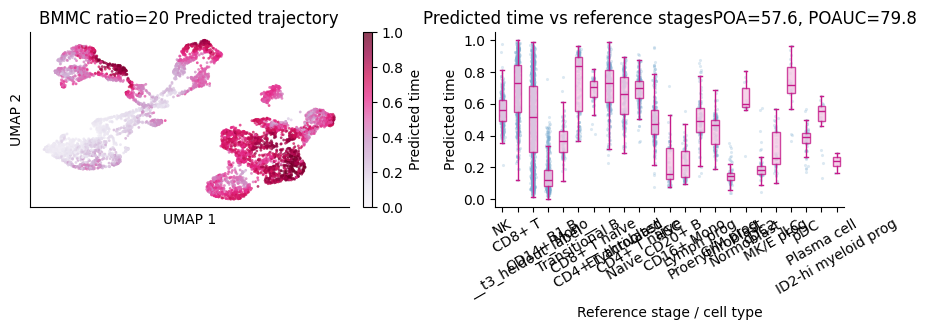

In [21]:

# Test C-plot on one run
ratio = 20
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
obj = inspect_run('consensus', ratio)
metaC = plot_trajectory_panel(axes[0], axes[1], obj['pred'], obj['metrics'], title_prefix=f'BMMC ratio={ratio}')
print('Trajectory meta:', metaC)
plt.tight_layout()
plt.show()


In [22]:

# =========================
# Combined Figure-3-like layout per ratio
# top row = consensus, bottom row = baseline
# =========================

def draw_ratio_figure(ratio: int, save=True, show=True):
    fig = plt.figure(figsize=(16, 8.5))
    gs = fig.add_gridspec(2, 6, width_ratios=[1.05, 1.05, 1.0, 0.85, 1.05, 1.1], wspace=0.38, hspace=0.55)

    col_titles = ['A. Cross-modal alignment', '', 'B. Cross-omics prediction', '', 'C. Predicted trajectory', '']
    row_titles = {'consensus': 'Consensus', 'baseline': 'Baseline'}

    for row, arm in enumerate(ARMS):
        obj = inspect_run(arm, ratio)
        pred = obj['pred']
        metrics = obj['metrics']
        if pred is None:
            raise FileNotFoundError(f'Missing predictions.npz for {arm} ratio={ratio}')

        ax_a1 = fig.add_subplot(gs[row, 0])
        ax_a2 = fig.add_subplot(gs[row, 1])
        ax_b1 = fig.add_subplot(gs[row, 2])
        ax_b2 = fig.add_subplot(gs[row, 3])
        ax_c1 = fig.add_subplot(gs[row, 4])
        ax_c2 = fig.add_subplot(gs[row, 5])

        plot_alignment_panel(ax_a1, ax_a2, pred, title_prefix=row_titles[arm])
        plot_prediction_panel(ax_b1, ax_b2, pred, metrics, title_prefix=row_titles[arm])
        plot_trajectory_panel(ax_c1, ax_c2, pred, metrics, title_prefix=row_titles[arm])

    fig.suptitle(f'BMMC multi-omics visualization (pairing ratio = {ratio}%)', fontsize=18, fontweight='bold', y=0.98)

    # Add panel letters at the top
    fig.text(0.03, 0.94, 'a', fontsize=24, fontweight='bold')
    fig.text(0.35, 0.94, 'b', fontsize=24, fontweight='bold')
    fig.text(0.65, 0.94, 'c', fontsize=24, fontweight='bold')

    caption = (
        f'Figure-like visualization on the BMMC dataset at pairing ratio {ratio}%. '
        'Top row: consensus; bottom row: baseline. '
        'a. Cross-modal alignment. '
        'b. Cross-omics prediction with true-vs-predicted RNA and prediction error. '
        'c. Trajectory inference with predicted time and reference stages.'
    )
    fig.text(0.5, 0.01, caption, ha='center', va='bottom', fontsize=11)

    if save:
        out_png = FIG_ROOT / f'BMMC_ratio_{ratio:03d}_figure3_like.png'
        out_pdf = FIG_ROOT / f'BMMC_ratio_{ratio:03d}_figure3_like.pdf'
        fig.savefig(out_png, dpi=250, bbox_inches='tight')
        fig.savefig(out_pdf, bbox_inches='tight')
        print(f'Saved: {out_png}')
        print(f'Saved: {out_pdf}')

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig



===== consensus | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 30) dtype=float64
    - t1_pred_pca          shape=(6191, 30) dtype=float64
    - time                 shape=(6191,) dtype=float32
    - time_head            shape=(6191,) dtype=float32
    - labels               shape=(6191,) dtype=<U20
  metrics keys: [

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)



===== baseline | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/baseline/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 30) dtype=float64
    - t1_pred_pca          shape=(6191, 30) dtype=float64
    - time                 shape=(6191,) dtype=float32
    - time_head            shape=(6191,) dtype=float32
    - labels               shape=(6191,) dtype=<U20
  metrics keys: ['d

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_020_figure3_like.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_020_figure3_like.pdf


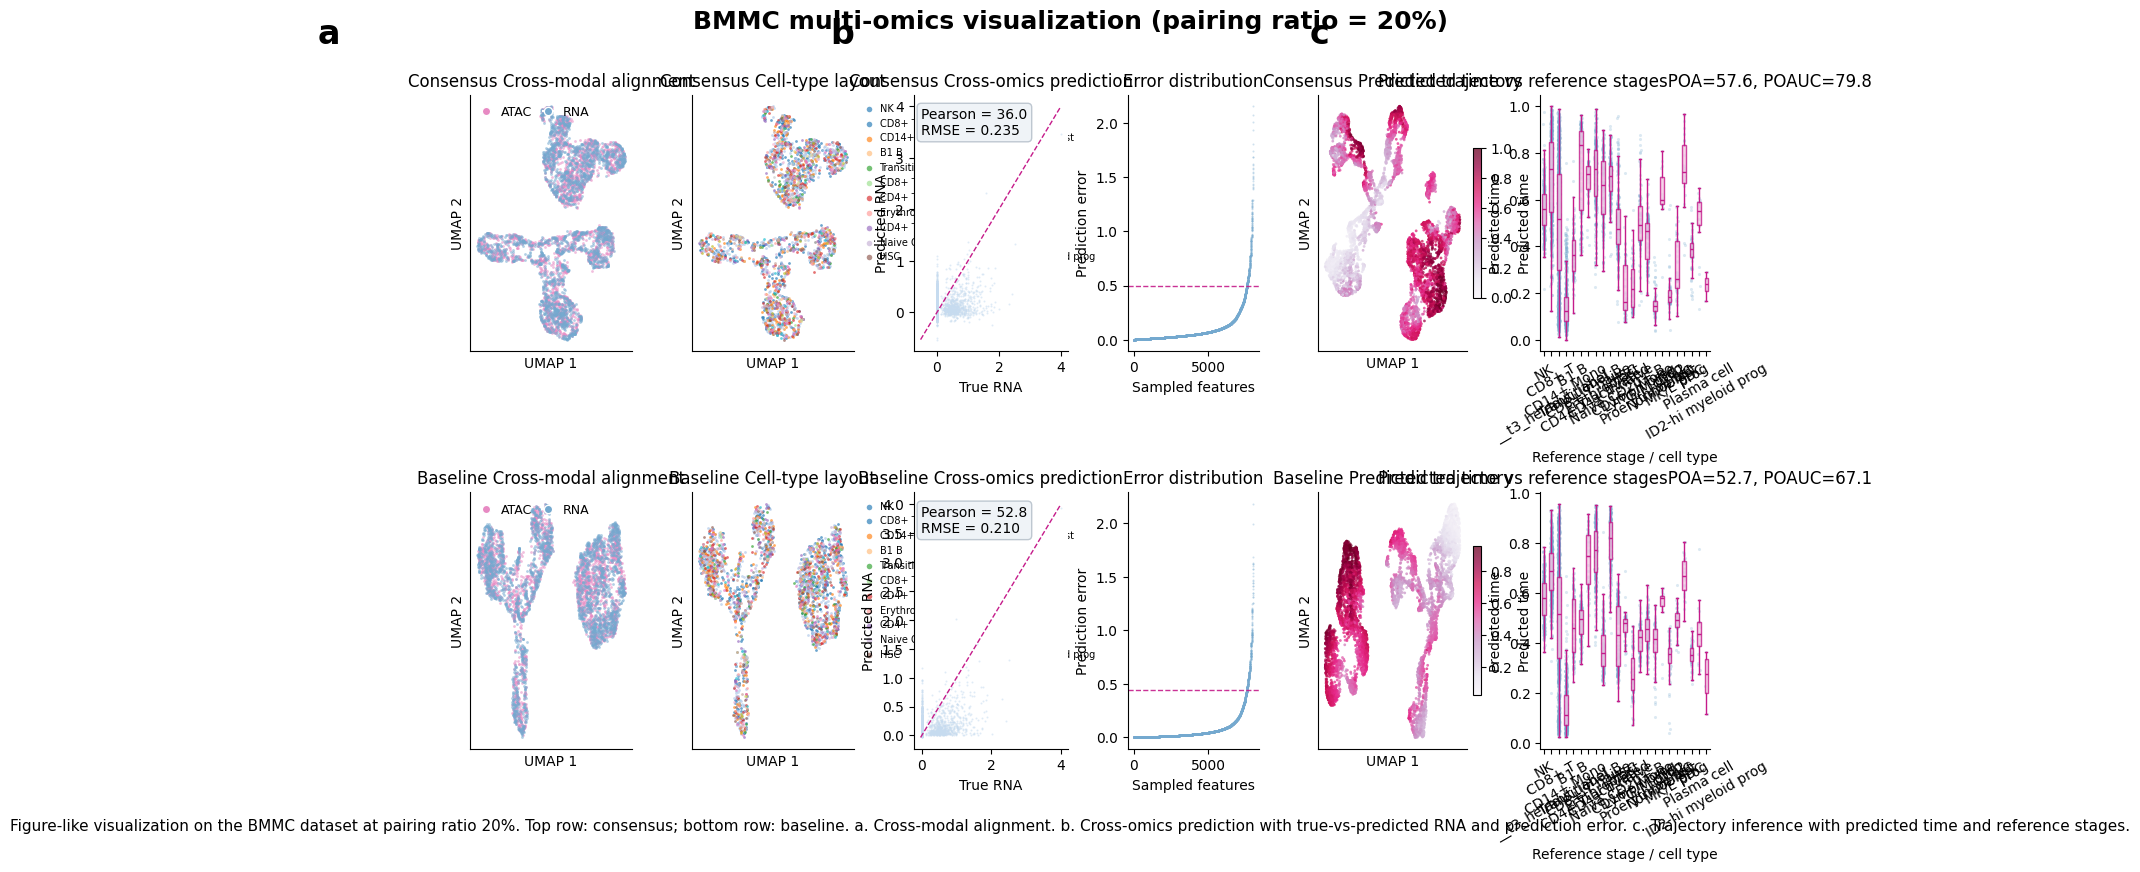

In [23]:

# Draw one ratio first
_ = draw_ratio_figure(20, save=True, show=True)


In [24]:

# Draw all ratios
for ratio in PAIR_RATIOS:
    _ = draw_ratio_figure(ratio, save=True, show=False)
print('All ratio figures are saved under:', FIG_ROOT)



===== consensus | ratio=0 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_000
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(5161,) dtype=<U25
    - z_atac               shape=(5161, 32) dtype=float32
    - z_rna                shape=(5161, 32) dtype=float32
    - h_fused              shape=(5161, 32) dtype=float32
    - pred_rna             shape=(5161, 12093) dtype=float32
    - true_rna             shape=(5161, 12093) dtype=float32
    - t1_true_pca          shape=(5161, 30) dtype=float64
    - t1_pred_pca          shape=(5161, 30) dtype=float64
    - time                 shape=(5161,) dtype=float32
    - time_head            shape=(5161,) dtype=float32
    - labels               shape=(5161,) dtype=<U20
  metrics keys: ['

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)



===== baseline | ratio=0 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/baseline/seed_1234/BMMC/pair_000
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(5161,) dtype=<U25
    - z_atac               shape=(5161, 32) dtype=float32
    - z_rna                shape=(5161, 32) dtype=float32
    - h_fused              shape=(5161, 32) dtype=float32
    - pred_rna             shape=(5161, 12093) dtype=float32
    - true_rna             shape=(5161, 12093) dtype=float32
    - t1_true_pca          shape=(5161, 30) dtype=float64
    - t1_pred_pca          shape=(5161, 30) dtype=float64
    - time                 shape=(5161,) dtype=float32
    - time_head            shape=(5161,) dtype=float32
    - labels               shape=(5161,) dtype=<U20
  metrics keys: ['da

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_000_figure3_like.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_000_figure3_like.pdf

===== consensus | ratio=20 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_020
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(6191,) dtype=<U25
    - z_atac               shape=(6191, 32) dtype=float32
    - z_rna                shape=(6191, 32) dtype=float32
    - h_fused              shape=(6191, 32) dtype=float32
    - pred_rna             shape=(6191, 12093) dtype=float32
    - true_rna             shape=(6191, 12093) dtype=float32
    - t1_true_pca          shape=(6191, 3

...

Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_080_figure3_like.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_080_figure3_like.pdf

===== consensus | ratio=100 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/consensus/seed_1234/BMMC/pair_100
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(10315,) dtype=<U25
    - z_atac               shape=(10315, 32) dtype=float32
    - z_rna                shape=(10315, 32) dtype=float32
    - h_fused              shape=(10315, 32) dtype=float32
    - pred_rna             shape=(10315, 12093) dtype=float32
    - true_rna             shape=(10315, 12093) dtype=float32
    - t1_true_pca          shape=(

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)



===== baseline | ratio=100 =====
Run dir: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/baseline/seed_1234/BMMC/pair_100
  metrics.json                   -> OK
  predictions.npz                -> OK
  summary.csv                    -> MISSING
  early_stopping_summary.json    -> OK
  t3_validation_partition.json   -> OK
  predictions.npz keys:
    - cell_ids             shape=(10315,) dtype=<U25
    - z_atac               shape=(10315, 32) dtype=float32
    - z_rna                shape=(10315, 32) dtype=float32
    - h_fused              shape=(10315, 32) dtype=float32
    - pred_rna             shape=(10315, 12093) dtype=float32
    - true_rna             shape=(10315, 12093) dtype=float32
    - t1_true_pca          shape=(10315, 30) dtype=float64
    - t1_pred_pca          shape=(10315, 30) dtype=float64
    - time                 shape=(10315,) dtype=float32
    - time_head            shape=(10315,) dtype=float32
    - labels               shape=(10315,) dtype=<U20
  metri

/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1395687748.py:46: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', max(1, len(unique_labels)))
/home/zhangye/anaconda3/envs/scmrdr/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_8150/1113537626.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_stage.boxplot(data, labels=order, patch_artist=True, showfliers=False)


Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_100_figure3_like.png
Saved: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like/BMMC_ratio_100_figure3_like.pdf
All ratio figures are saved under: /data5/zhangye/ATLAS/results/t3_early_stop/BMMC_full_01/visualization_BMMC_figure3_like


In [25]:

# Optional: separate output directories for A / B / C-only figures if you want cleaner paper editing.
ALIGN_DIR = FIG_ROOT / 'A_alignment_only'
PRED_DIR = FIG_ROOT / 'B_prediction_only'
TRAJ_DIR = FIG_ROOT / 'C_trajectory_only'
for d in [ALIGN_DIR, PRED_DIR, TRAJ_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def save_single_task_panels(ratio: int):
    for task_name, out_dir in [('A', ALIGN_DIR), ('B', PRED_DIR), ('C', TRAJ_DIR)]:
        fig, axes = plt.subplots(2, 2 if task_name != 'B' and task_name != 'C' else 2, figsize=(8.5, 6.2))
        for row, arm in enumerate(ARMS):
            obj = inspect_run(arm, ratio)
            pred = obj['pred']
            metrics = obj['metrics']
            if task_name == 'A':
                plot_alignment_panel(axes[row, 0], axes[row, 1], pred, title_prefix=arm.capitalize())
            elif task_name == 'B':
                plot_prediction_panel(axes[row, 0], axes[row, 1], pred, metrics, title_prefix=arm.capitalize())
            else:
                plot_trajectory_panel(axes[row, 0], axes[row, 1], pred, metrics, title_prefix=arm.capitalize())
        fig.suptitle(f'{task_name} only | BMMC ratio={ratio}%', fontsize=16, fontweight='bold')
        out = out_dir / f'{task_name}_BMMC_ratio_{ratio:03d}.png'
        fig.savefig(out, dpi=250, bbox_inches='tight')
        plt.close(fig)
        print('Saved:', out)

# Example:
# save_single_task_panels(20)



## Notes

1. **Inspect first, then batch export.**
   Because different runs may save slightly different arrays, the notebook first shows the available `predictions.npz` keys.

2. **If trajectory labels are missing**, set:
   - `EXTERNAL_LABEL_CSV`
   - `EXTERNAL_LABEL_CELL_ID_COL`
   - `EXTERNAL_LABEL_COL`

3. **If alignment keys are different**, modify `get_alignment_embeddings()`.

4. **If true / predicted RNA keys are different**, modify `get_prediction_arrays()`.

5. The current notebook emphasizes:
   - a **paper-friendly layout**,
   - **pink / blue colors** similar to your reference image,
   - and **ratio-wise figure export** for 0–100 pairing ratios.
